# Large shocks and local approximations

How well do approximations from first to third order capture the behavior of consumption after large fiscal shocks? Following the paper's appendix D ("Quantifying Nonlinearities"), here we explore this question with our model, comparing perturbation approximations to a fully nonlinear MIT-shock impulse response as we vary several features of the fiscal shock.

Our conclusion is that third-order approximation, and sometimes even first- or second-order approximation, generally does quite well, except in the special case where most or all of the following are true:
- The shock is extremely large (say, 10% of GDP)

- It is a lump-sum transfer rather than a proportional tax cut

- The shock is one-time-only rather than even moderately persistent

- We care about the impact effect on consumption rather than, say, the cumulative effect over the first two quarters

We suspect that the combination of all these features is rare (and possibly nonexistent) in real-world fiscal shocks. To illustrate this, we conclude by considering a fiscal shock with size and persistence drawn from the largest deficit increase in postwar US history—the 2020 COVID shock—and argue that even a shock of this unusual magnitude is well-captured by third-order perturbation.

# 0. Setup (including plotting functions)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from smooth_sim.model import paper_household
from analytical_fast.backward import Backward
from analytical_fast.forward import Forward
from sequence_space.paths import first_order, second_order, third_order
from sequence_space.jacobian import income_jacobian_analytical

plt.rcParams.update({"figure.figsize": (10, 3), "font.size": 11, "legend.fontsize": 9})
T = 300
hh, ss = paper_household()
backward, forward = Backward(hh, ss), Forward(hh, ss)
zero = hh.transition(ss, dZ=np.zeros(T))
sizes = np.linspace(-0.10, 0.10, 11)
print("Steady-state of model:")
print(f"Assets: {ss['A']:.3f}; consumption: {ss['C']:.3f}; transfers: {ss['Tr']:.2f}")

Steady-state of model:
Assets: 4.000; consumption: 0.830; transfers: 0.14


We'll be repeatedly comparing exact nonlinear MIT shock results with perturbation results up to third order, comparing both date-0 impact responses, date-1 responses, and cumulative responses over the first two quarters. Plotting code for this below:

In [2]:
def plot_orders(ax, x, exact, approximations):
    ax.plot(x, 100*exact, "k-", label="Perfect foresight")
    ax.plot(x, 100*approximations[0], "C0--", label="First order")
    ax.plot(x, 100*approximations[1], "C1:", label="Second order")
    ax.plot(x, 100*approximations[2], "C2-.", label="Third order")


def size_panels(axes, exact, approximations):
    plot_orders(axes[0], 100*sizes, exact[:, 0], approximations[:, :, 0])
    plot_orders(axes[1], 100*sizes, exact[:, 1], approximations[:, :, 1])
    plot_orders(axes[2], 100*sizes, exact[:, :2].sum(axis=1),
                approximations[:, :, :2].sum(axis=2))
    for ax, title in zip(axes, ("Impact", "Date 1", "First two quarters")):
        ax.set(title=title, xlabel="Impact shock (% of GDP)")
        ax.axhline(0, color="0.85", lw=0.7)

## 1. Proportional income shocks: impact versus cumulative spending

Household cash on hand is
$$m_t=(1+r)a_{t-1}+Z_t e_t\xi_t+Tr_t,$$
where $Z_t$ is aggregate after-tax labor income, $e_t\xi_t$ is relative earnings with mean one, and $Tr_t$ is a lump-sum transfer. Steady-state quarterly GDP is one.

We vary the one-time shock $\Delta Z_0=\nu$ from −10% to +10% of GDP, holding transfers fixed. Each household receives $\nu e_0\xi_0$, so the aggregate injection is $\nu$.

As in notebook 2, we obtain consumption derivatives from the household budget:
$$\Delta C_t=\Delta Z_t+\Delta Tr_t+(1+r)\Delta A_{t-1}-\Delta A_t.$$

In [3]:
def taylor(derivatives, amplitudes):
    dC, d2C, d3C = derivatives
    nu = amplitudes[:, None]
    first = nu*dC
    second = first + nu**2*d2C/2
    third = second + nu**3*d3C/6
    return np.array([first, second, third])


def pe_responses(z, lump_share, amplitudes=sizes):
    du = np.zeros((len(z), 3))  # Columns: r, Z, Tr.
    du[:, 1], du[:, 2] = (1-lump_share)*z, lump_share*z
    d = third_order(backward, forward, du)
    dA = np.array([d['dA'], d['d2A'], d['d3A']])
    dA_lag = np.zeros_like(dA)  # Initial assets are fixed.
    dA_lag[:, 1:] = dA[:, :-1]
    dC = (1+ss['r'])*dA_lag-dA
    dC[0] += z  # Income changes only at first order.
    exact = np.array([hh.transition(ss, dZ=nu*du[:, 1], dTr=nu*du[:, 2])['C']
                      - zero['C'][:len(z)] for nu in amplitudes])
    return taylor(dC, amplitudes), exact

Below we plot consumption as a function of the income shock at date 0, date 1, and for these two quarters cumulatively. The impact and date-1 panels correspond to paper **Figure 2**; the cumulative panel corresponds to **Figure D.1(a)**.

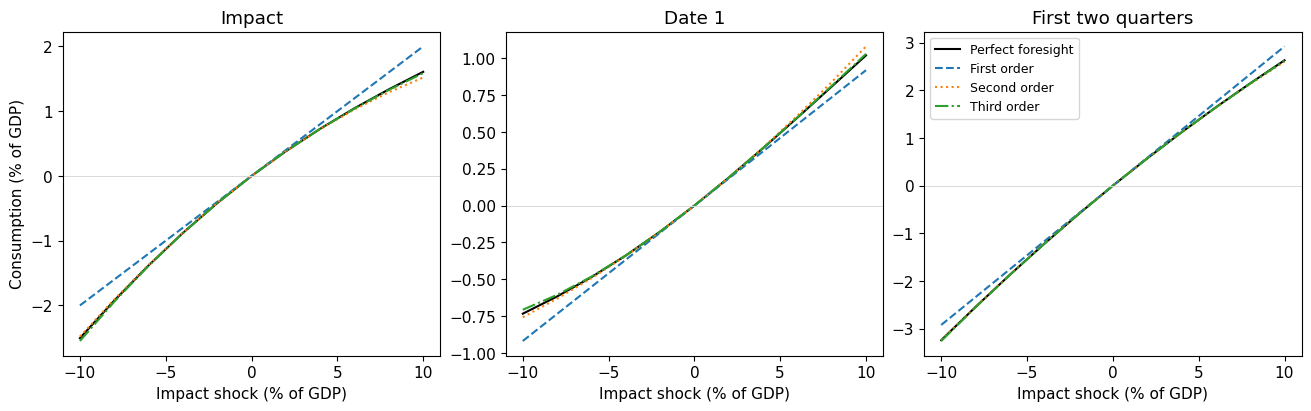

In [4]:
# Paper Figure 2: left and middle panels; Figure D.1(a): right panel.
z = np.zeros(T); z[0] = 1
approx_prop, exact_prop = pe_responses(z, lump_share=0)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_prop, approx_prop)
axes[0].set_ylabel("Consumption (% of GDP)")
axes[-1].legend();

We see that the impact response is concave and the next-quarter response is convex. Both are well-captured by second-order and especially third-order approximations.

Adding them offsets much of the curvature, bringing even the linear approximation closer to the nonlinear benchmark, and making both second- and third-order approximations quite accurate.

## 2. Lump-sum transfers

We now consider the same one-time aggregate income shock delivered as a lump-sum transfer. We change $Tr_t$ rather than $Z_t$, so every household receives the same amount, rather than an amount proportional to earnings. This makes the shock larger relative to the income of low-earning households, who are more likely to be near the constraint (as emphasized by Bianchi and Kaplan 2026). Note that even at the −10% endpoint, transfers remain positive, since their steady-state level is 14% of GDP.

This figure corresponds to paper **Figure D.2**.

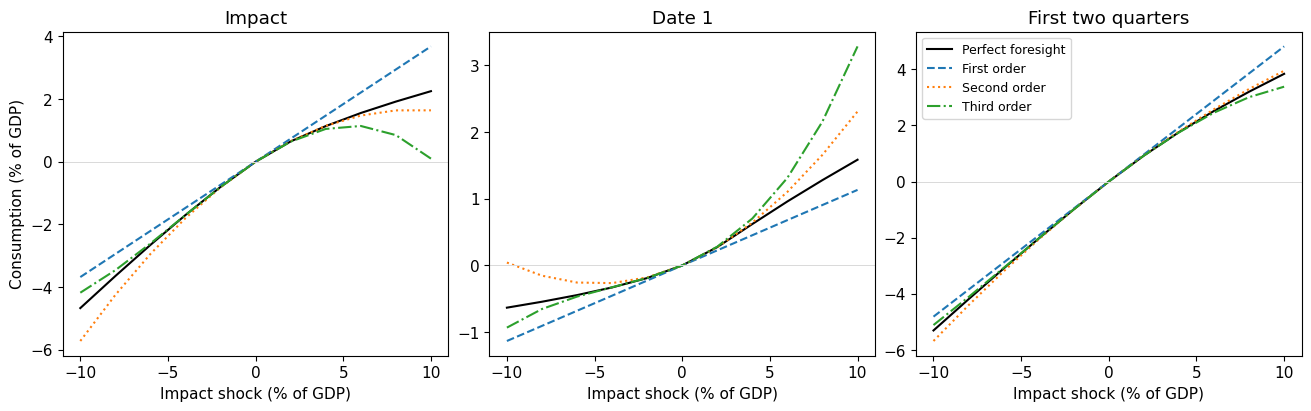

In [5]:
# Paper Figure D.2.
approx_lump, exact_lump = pe_responses(z, lump_share=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_lump, approx_lump)
axes[0].set_ylabel("Consumption (% of GDP)")
axes[-1].legend();

We see that the one-time lump-sum transfer is much harder to approximate on impact than the proportional income shock. For very large positive transfers, third order actually does worse than second order. Much of this error reverses in the next quarter, however, so adding the two quarters again makes the approximations substantially more accurate.

To get a sense of magnitude: prior to Covid, the largest-ever "stimulus checks" in modern US history were the rebates from the Economic Stimulus Act of 2008, at slightly less than \$100 billion, or roughly 2.5\% of GDP. This is well within the range where third-order approximation remains accurate.

During the Covid pandemic, however, the March 2021 round of checks totalled about $400 billion, or slightly over 7\% of GDP—outside the range of accurate approximation here. We will argue at the end of this notebook that when the Covid pandemic is taken as a whole, including the role of persistence (discussed below), third-order approximation remains remarkably accurate; but taken in isolation, Covid-sized checks are potentially a case where this kind of perturbation breaks down.

(For comparison of magnitudes with Bianchi and Kaplan's work, note that they specify transfers as fractions of *annual* GDP, so their x-axis, which goes up to 15\% of annual GDP, has an upper limit of 60\% of quarterly GDP, more than 8 times larger as a share of GDP than the largest-ever round of stimulus checks.)

## 3. Persistence

We next keep the lump-sum allocation across households and change the timing of the shock. Instead of a one-time transfer, we let transfers decay gradually, with $\Delta Tr_t=\nu\,0.7^t$. The impact size is unchanged, although the persistent shock delivers more income in total. Anticipation matters here: households know from the outset that further transfers are coming.

The figure below corresponds to paper **Figure D.3**.

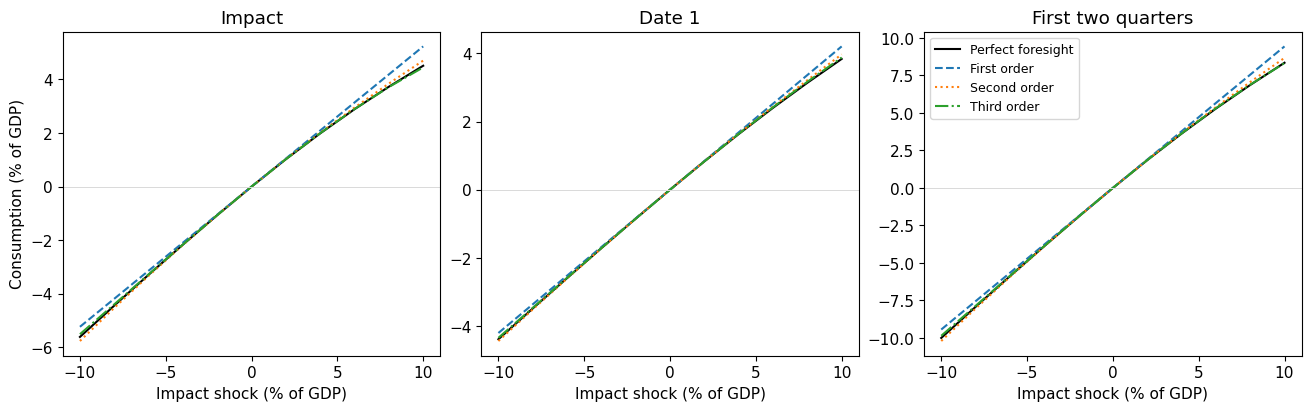

In [6]:
# Paper Figure D.3.
z_persistent = 0.7**np.arange(T)
approx_persistent, exact_persistent = pe_responses(z_persistent, lump_share=1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_persistent, approx_persistent)
axes[0].set_ylabel("Consumption (% of GDP)")
axes[-1].legend();

We see that even the impact response is now much closer to linear. Second- and third-order approximations are quite accurate across all three panels, despite the larger total income injection. The difficulty with large lump-sum transfers thus depends strongly on how concentrated they are in time.

The intuition is that the incentive to save depends on today's income relative to income in the future. A large one-time transfer makes today unusually flush, so even households initially at the borrowing constraint may want to save some of it for later. As the transfer grows and households move away from the constraint, they spend a smaller share of each additional dollar on impact, making the consumption response concave.

With persistence, however, households also expect higher transfers in the future. There is therefore less reason to save out of today's transfer: the same initial receipt does less to push households away from the borrowing constraint. Their marginal propensity to spend on impact falls less as the shock grows, helping explain why the aggregate response is much closer to linear.

It is interesting to note here that even though higher persistence, conditional on the same impact transfer shock, makes the cumulative transfer much *larger*, the nonlinearity is nevertheless much *smaller*.

## 4. Debt-financed fiscal shocks in general equilibrium

We now let after-tax labor income adjust to clear the asset market, as in notebook 1. Interest rates and government purchases remain fixed, so output and consumption changes coincide, $\Delta Y_t=\Delta C_t$. We use output for the GE results.

We first compare a one-time proportional tax cut with a one-time lump-sum transfer. Both raise government debt by $\nu$ on impact, followed by gradual repayment through proportional taxes: $b_t=\nu\,0.95^t$, where $b_t$ is debt relative to steady state. They differ only in who receives the initial stimulus: households benefit in proportion to earnings from the tax cut, but receive equal amounts from the lump-sum transfer. The horizontal axis now measures the initial debt increase.

We use the one-shot principle (**Proposition 7**), as in notebook 1, to find the income response that makes household saving match government debt, first at first order and then with second- and third-order corrections.

In [7]:
J = income_jacobian_analytical(backward, forward, T)
rho_B = 0.95


def ge_derivatives(debt, transfers):
    du, d2u = np.zeros((2, T, 3))
    du[:, 2] = transfers
    direct = first_order(backward, forward, du)['dA']
    du[:, 1] = np.linalg.solve(J, debt-direct)
    d2u[:, 1] = np.linalg.solve(J, -second_order(backward, forward, du)['d2A'])
    d3Z = np.linalg.solve(J, -third_order(backward, forward, du, d2u)['d3A'])
    dZ = np.array([du[:, 1], d2u[:, 1], d3Z])
    # With fixed G and r, the government budget pins down tax revenue:
    # dTax = transfers + (1+r)*debt_lag - debt.
    # Since dZ = dY - dTax, output is dZ + dTax.
    dY = dZ.copy()
    dY[0] += transfers+(1+ss['r'])*np.concatenate(([0.], debt[:-1]))-debt
    return dZ, dY

For comparison, we also solve for the fully nonlinear equilibrium. Starting from the first-order income response, we adjust the income path until household saving matches government debt at every date. The reported asset-market residual checks that the remaining discrepancy is less than $10^{-9}$ of quarterly GDP.

In [8]:
def ge_nonlinear(nu, debt, transfers, dZ1):
    dZ = nu*dZ1.copy()
    for _ in range(60):
        path = hh.transition(ss, dZ=dZ, dTr=nu*transfers)
        error = path['A']-ss['A']-nu*debt
        if np.max(abs(error)) < 1e-9:
            return path['C']-zero['C'], np.max(abs(error))
        dZ -= np.linalg.solve(J, error)
    raise RuntimeError("Asset market did not clear")


def ge_responses(debt, transfers):
    dZ, dY = ge_derivatives(debt, transfers)
    solutions = [ge_nonlinear(nu, debt, transfers, dZ[0]) for nu in sizes]
    exact = np.array([response for response, error in solutions])
    print(f"Maximum asset-market residual: {max(error for response, error in solutions):.1e}")
    return taylor(dY, sizes), exact

We first consider the proportional tax cut, looking at output on impact, at date 1, and over the first two quarters. Does the additional spending generated in general equilibrium make these responses harder to approximate than their partial-equilibrium counterparts?

The impact and date-1 panels correspond to paper **Figure B.4**. The cumulative panel corresponds to **Figure D.1(b)**.

Maximum asset-market residual: 8.9e-10


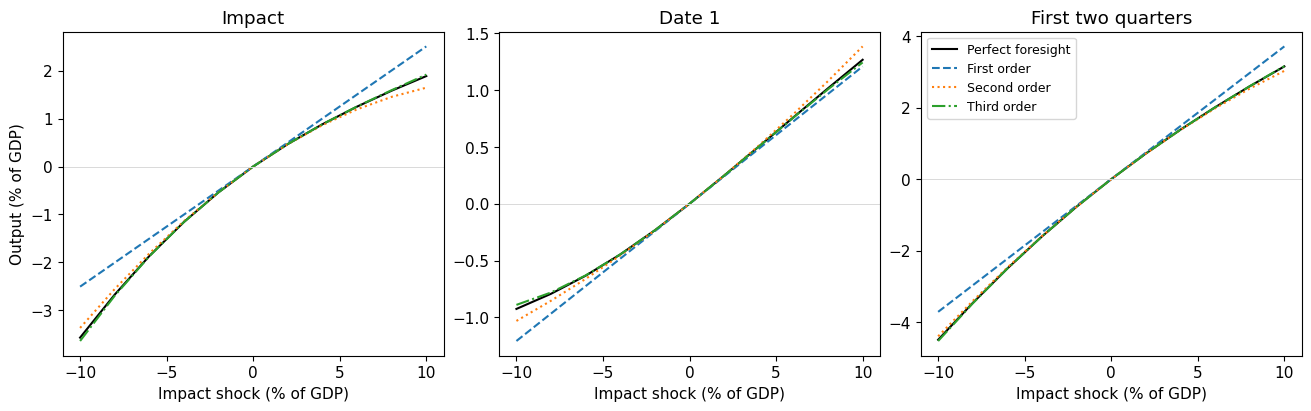

In [9]:
# Paper Figure B.4: left and middle panels; Figure D.1(b): right panel.
debt_prop = rho_B**np.arange(T)
approx_ge_prop, exact_ge_prop = ge_responses(debt_prop, np.zeros(T))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_ge_prop, approx_ge_prop)
axes[0].set_ylabel("Output (% of GDP)")
axes[-1].legend();

We again see concavity on impact and convexity at date 1, with much of the curvature offset when we add the two quarters. Equilibrium feedback amplifies the output responses, but second- and especially third-order approximations remain quite accurate.

We next deliver the same initial stimulus as a one-time lump-sum transfer, keeping the debt path unchanged. This corresponds to paper **Figure D.4**.

Maximum asset-market residual: 6.9e-10


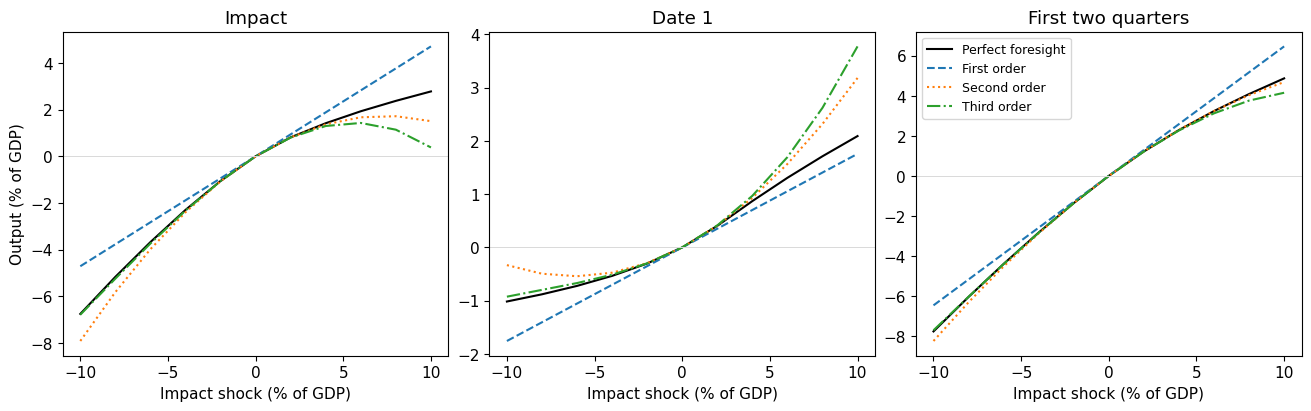

In [10]:
# Paper Figure D.4.
approx_ge_lump, exact_ge_lump = ge_responses(debt_prop, z)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_ge_lump, approx_ge_lump)
axes[0].set_ylabel("Output (% of GDP)")
axes[-1].legend();

The pattern is much the same as in partial equilibrium. Large one-time lump-sum transfers are difficult to approximate on impact, but adding the next quarter offsets much of the error.

### Persistent transfers

Finally, we let the lump-sum transfer persist, with $\Delta Tr_t=\nu\,0.7^t$, as in the earlier partial-equilibrium experiment. Each additional transfer is financed by borrowing, while existing debt continues to be repaid at the same rate. The debt path therefore becomes
$$b_t=0.95b_{t-1}+\Delta Tr_t,\qquad b_{-1}=0.$$
For a one-time transfer this reduces to the debt path used above; with persistence, later payments add to debt as well.

Proportional taxes again adjust to satisfy the government budget. The figure below corresponds to paper **Figure D.5**.

Maximum asset-market residual: 8.9e-10


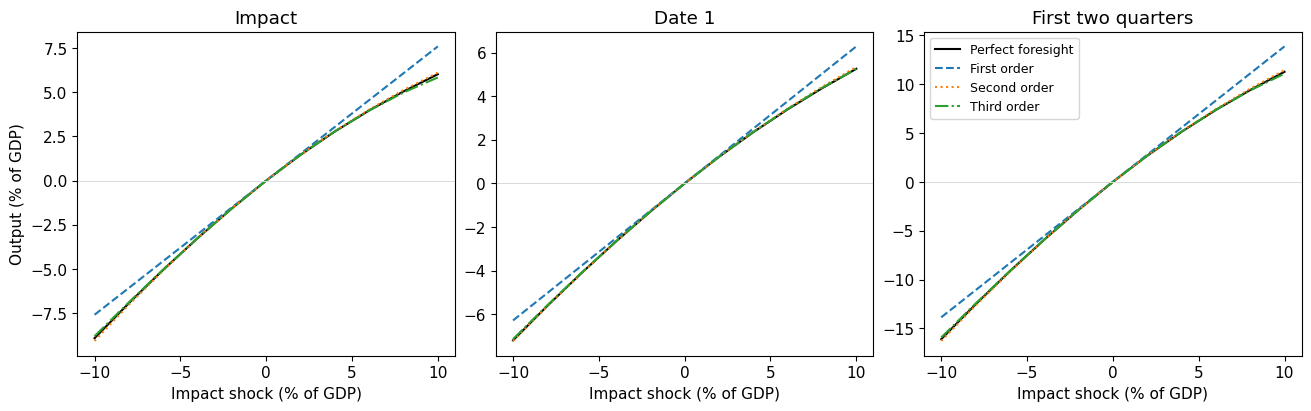

In [11]:
# Paper Figure D.5.
def fiscal_debt(transfers):
    debt = np.zeros(T)
    for t in range(T):
        debt[t] = transfers[t] + (rho_B*debt[t-1] if t else 0.)
    return debt


approx_ge_persistent, exact_ge_persistent = ge_responses(fiscal_debt(z_persistent), z_persistent)
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
size_panels(axes, exact_ge_persistent, approx_ge_persistent)
axes[0].set_ylabel("Output (% of GDP)")
axes[-1].legend();

With persistent transfers, second- and third-order approximations are quite accurate both on impact and over the first two quarters. As in partial equilibrium, persistence substantially reduces the nonlinearity, even though the total transfer is larger.

## 5. A COVID-sized shock: lump-sum, proportional, and mixed transfers

Finally, we return to partial equilibrium and consider the stylized COVID-sized shock from the paper's Appendix D ("Quantifying nonlinearities"), $s_t=0.20\times0.7^t$. As described there, this path approximately matches the COVID-era increase in U.S. federal deficits as a share of potential GDP, measured relative to the ratio's 2019Q4 baseline. The shock starts at 20% of steady-state quarterly GDP, twice the largest positive shock above, and has the same persistence as our earlier persistent transfers.

We compare three ways of delivering this income: entirely through lump-sum transfers, entirely through proportional income increases, and through a 50/50 mix. We view the mixed case as more plausible: some of the deficit financed direct household transfers, while some supported firms in making payroll, benefiting households more in proportion to earnings. The 50/50 split is a stylized assumption, and we include the two pure cases for comparison.

Below we plot the consumption paths over time, rather than varying shock size. This corresponds to paper **Figure D.6**.

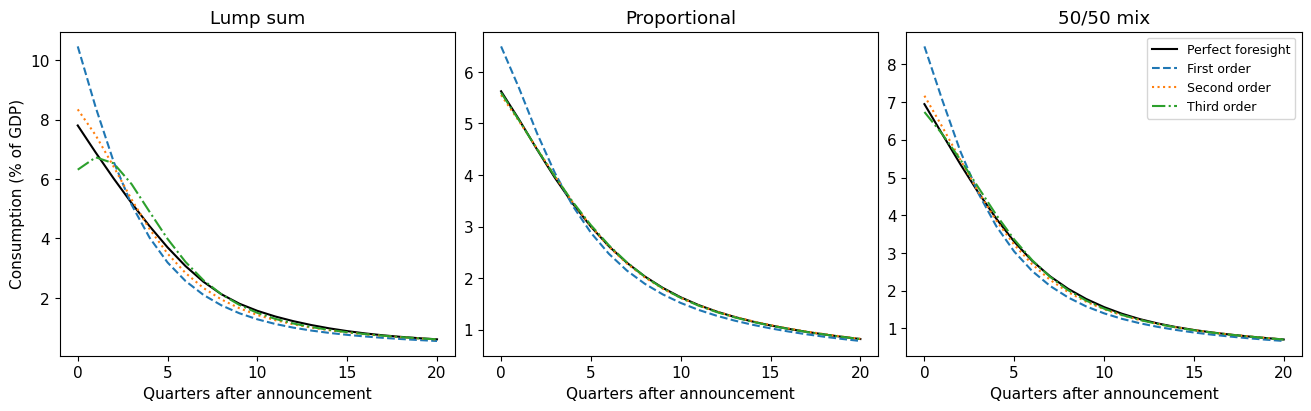

In [12]:
# Paper Figure D.6.
covid_size = np.array([0.20])
fig, axes = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
covid_errors = []
for ax, share, title in zip(axes, (1., 0., 0.5), ("Lump sum", "Proportional", "50/50 mix")):
    approx, exact = pe_responses(z_persistent, share, covid_size)
    plot_orders(ax, np.arange(21), exact[0, :21], approx[:, 0, :21])
    ax.set(title=title, xlabel="Quarters after announcement")
    covid_errors.append(100*(approx[:, 0, :2]-exact[0, :2]))
axes[0].set_ylabel("Consumption (% of GDP)")
axes[-1].legend();

We see that second- and third-order approximations track the proportional and mixed shocks closely, even at this unusually large size. The pure lump-sum shock remains harder to approximate, with third order doing worse than second order on impact.

To quantify these differences, we report absolute approximation errors on impact and for cumulative consumption over the first two quarters. For the cumulative response, we add the two quarters’ errors before taking the absolute value, so they can offset each other. Both are measured as percentages of steady-state quarterly GDP.

In [13]:
print("Absolute error (% of quarterly GDP); columns are orders 1, 2, 3")
for name, error in zip(("Lump sum", "Proportional", "50/50 mix"), covid_errors):
    impact_error, cumulative_error = abs(error[:, 0]), abs(error.sum(axis=1))
    print(f"{name:12s} impact: {impact_error.round(3)}; first two quarters: {cumulative_error.round(3)}")

Absolute error (% of quarterly GDP); columns are orders 1, 2, 3
Lump sum     impact: [2.661 0.542 1.488]; first two quarters: [4.18  1.122 1.648]
Proportional impact: [0.871 0.073 0.029]; first two quarters: [1.482 0.106 0.043]
50/50 mix    impact: [1.532 0.223 0.209]; first two quarters: [2.434 0.418 0.205]


For the proportional shock, the third-order error is only about 0.03% of quarterly GDP on impact and 0.04% over the first two quarters. For the 50/50 mix, it is about 0.21% at either horizon. Even a shock of this exceptional size is therefore reasonably well captured by third-order perturbation in both the proportional and mixed cases. We view this good performance as a favorable result from a demanding stress test of perturbation—given the fact that the Covid pandemic was an exceptional, unanticipated one-time event in modern US history, we would feel comfortable advising nonlinear MIT shocks rather than perturbation (whose main advantage is capturing how ongoing aggregate risk affects behavior) for a pandemic-sized shock, but perturbation seems to nevertheless acquit itself well.

For the extreme case of a pure lump-sum 20\% of GDP shock, by contrast, third-order errors are about 1.49% of quarterly GDP on impact and 1.65% over the first two quarters, larger than the second-order errors at both horizons. Here, adding the next quarter does not resolve the approximation error.

Third-order perturbation thus struggles most when we combine an extremely large shock, purely lump-sum incidence, no persistence, and a focus on impact consumption. Proportional income gains, even moderate persistence, or adding the next quarter generally make the approximation much more accurate. We suspect that this unusually unfavorable combination is rare in actual fiscal interventions: even for the exceptional COVID episode, allowing for the observed persistence and a plausible mix of lump-sum and proportional income gains gives a reasonably accurate third-order response.